Question 4: Data Check


In [23]:
#importing stuff
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8')
mpl.rcParams['font.family'] = 'serif'
%matplotlib inline

In [24]:
#set working directory (not local)
import os
#L1 = 'C:/Users/Michelle Alessandra/HWdata'
#print(L1)
#os.chdir(L1)
os.listdir()

['.config', 'mystock_raw.csv', 'dj.csv', 'sample_data']

In [25]:
#reading the csv and checking first few lines
dj = pd.read_csv("dj.csv")
dj.head()

,Unnamed: 0,date,dji
0,0,1896-05-26,40.94
1,1,1896-05-27,40.58
2,2,1896-05-28,40.20
3,3,1896-05-29,40.63
4,4,1896-06-01,40.60


In [26]:
dj.info() # 1 missing dji

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28073 entries, 0 to 28072
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  28073 non-null  int64  
 1   date        28073 non-null  object 
 2   dji         28072 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 658.1+ KB


In [27]:
dj.isna().sum()

,0
Unnamed: 0,0
date,0
dji,1


In [28]:
#convert dates and sort data
dj['date'] = pd.to_datetime(dj['date'])
dj = dj.sort_values('date')
dj['date'].is_monotonic_increasing

True

In [29]:
#check for duplicate dates
dj['date'].duplicated().sum()
dj[dj['date'].duplicated(keep=False)]

,Unnamed: 0,date,dji


In [30]:
dj.describe()

,Unnamed: 0,date,dji
count,28073.00000,28073,28072.000000
mean,14036.00000,1952-09-10 01:49:00.091903232,1669.659860
min,0.00000,1896-05-26 00:00:00,0.000000
25%,7018.00000,1924-10-06 00:00:00,98.027500
50%,14036.00000,1952-11-05 00:00:00,284.640000
75%,21054.00000,1980-10-17 00:00:00,964.765000
max,28072.00000,2008-06-19 00:00:00,14164.530000
std,8104.12139,NaN,3099.652164


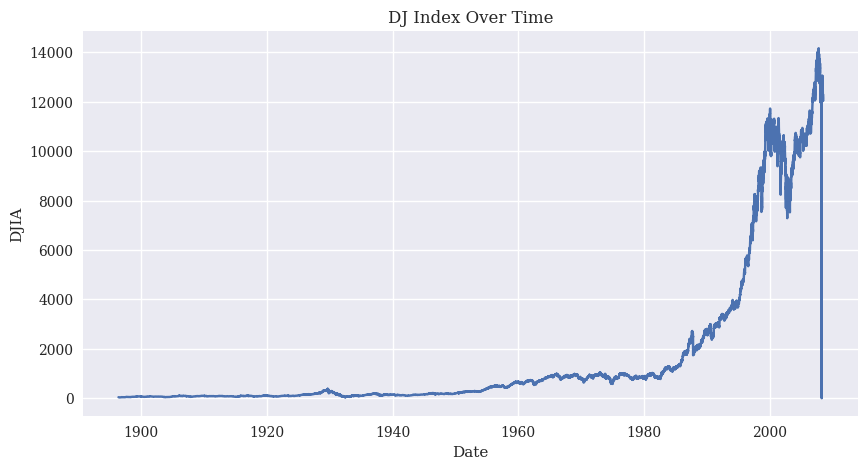

In [31]:
# checking trend (DJI vs. Time)
plt.figure(figsize=(10,5))
plt.plot(dj['date'], dj['dji'])  # use 'dji' column
plt.title("DJ Index Over Time")
plt.xlabel("Date")
plt.ylabel("DJIA")
plt.show()

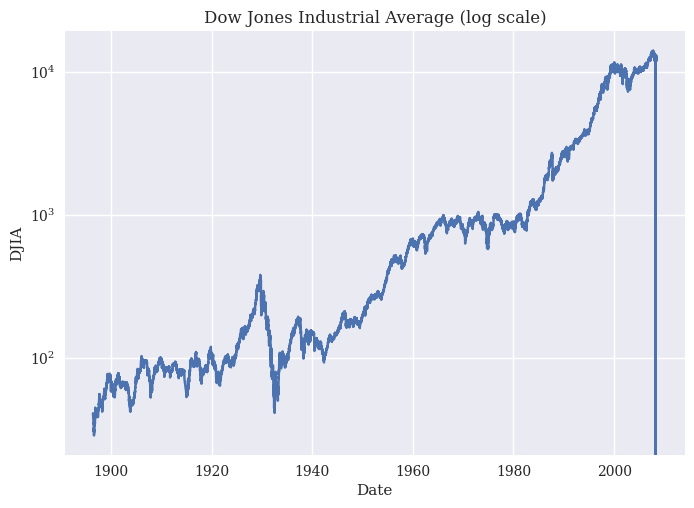

In [51]:
# checking trend (on log-scale)
import matplotlib.pyplot as plt
plt.plot(dj['date'], dj['dji'])
plt.yscale('log')
plt.xlabel('Date')
plt.ylabel('DJIA')
plt.title('Dow Jones Industrial Average (log scale)')
plt.show()

In [53]:
print(dj.columns)

Index(['Unnamed: 0', 'date', 'dji'], dtype='object')


/tmp/ipython-input-1049172133.py:2: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  dj['returns'] = dj['dji'].pct_change()


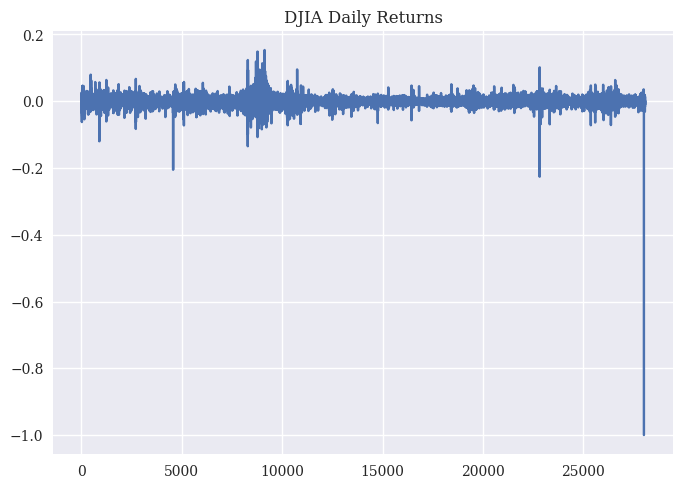

In [57]:
# checking return trend (% change)d
dj['returns'] = dj['dji'].pct_change()
dj['returns'].plot()
plt.title('DJIA Daily Returns')
plt.show()

Question 5: MSFT vs. AAPL Long-Short Strategy

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [35]:
mystock = pd.read_csv('mystock_raw.csv')
mystock.head()

,Unnamed: 0,permno,date,bidlo,askhi,openprc,prc,vol
0,0,10107,2015-01-02,46.54,47.4200,46.66,46.760,27913852.0
1,1,10107,2015-01-05,46.25,46.7300,46.37,46.325,39673865.0
2,2,10107,2015-01-06,45.54,46.7490,46.38,45.650,36447854.0
3,3,10107,2015-01-07,45.49,46.4600,45.98,46.230,29222067.0
4,4,10107,2015-01-08,46.72,47.7499,46.75,47.590,29645202.0


In [36]:
mystock['date'] = pd.to_datetime(mystock['date'])
mystock = mystock.sort_values('date')
mystock.head()

,Unnamed: 0,permno,date,bidlo,askhi,openprc,prc,vol
0,0,10107,2015-01-02,46.54,47.420,46.66,46.760,27913852.0
2517,2517,14593,2015-01-02,107.35,111.440,111.39,109.330,53204828.0
2518,2518,14593,2015-01-05,105.41,108.650,108.29,106.250,64289001.0
1,1,10107,2015-01-05,46.25,46.730,46.37,46.325,39673865.0
2,2,10107,2015-01-06,45.54,46.749,46.38,45.650,36447854.0


In [37]:
# filter pre-split data
split_date = '2020-08-31'
mystock_pre_split = mystock[mystock['date'] < split_date].copy()

# identify by permno (from lecture notes)
msft_permno = 14593
aapl_permno = 10107

msft = mystock[mystock['permno'] == msft_permno][['date','prc']].rename(columns={'prc':'MSFT_price'})
aapl = mystock[mystock['permno'] == aapl_permno][['date','prc']].rename(columns={'prc':'AAPL_price'})

# merge by date
mystock_prices = pd.merge(msft, aapl, on='date', how='inner')
mystock_prices['date'] = pd.to_datetime(mystock_prices['date'])
mystock_prices = mystock_prices.sort_values('date')
mystock_prices.head()


,date,MSFT_price,AAPL_price
0,2015-01-02,109.33,46.760
1,2015-01-05,106.25,46.325
2,2015-01-06,106.26,45.650
3,2015-01-07,107.75,46.230
4,2015-01-08,111.89,47.590


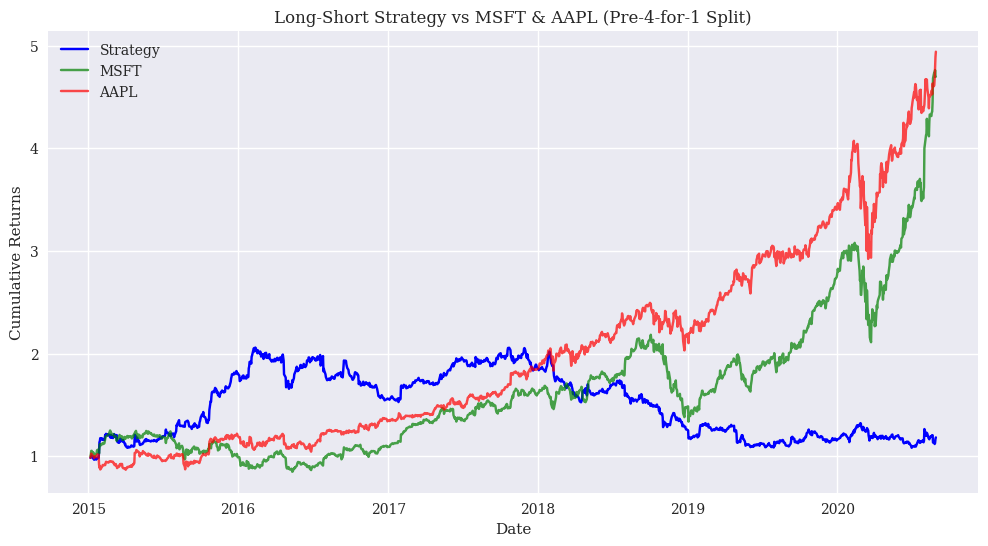

In [38]:
# filter before split
split_date = '2020-08-31'
mystock_prices = mystock_prices[mystock_prices['date'] < split_date].copy()

# calculate daily returns
mystock_prices['msft_ret'] = mystock_prices['MSFT_price'].pct_change()
mystock_prices['aapl_ret'] = mystock_prices['AAPL_price'].pct_change()
mystock_prices = mystock_prices.dropna(subset=['msft_ret','aapl_ret'])

# create yesterday's returns
mystock_prices['msft_ret_y'] = mystock_prices['msft_ret'].shift(1)
mystock_prices['aapl_ret_y'] = mystock_prices['aapl_ret'].shift(1)
mystock_prices = mystock_prices.dropna(subset=['msft_ret_y','aapl_ret_y'])

# the signal
mystock_prices['mysignal'] = np.where(mystock_prices['msft_ret_y'] > mystock_prices['aapl_ret_y'], 1, -1)
mystock_prices['strat_ret'] = mystock_prices['mysignal'] * (mystock_prices['msft_ret'] - mystock_prices['aapl_ret'])
mystock_prices['cum_strat_ret'] = (1 + mystock_prices['strat_ret']).cumprod()
# print(mystock_prices['mysignal'])

# plot performance

# strategy only
# plt.figure(figsize=(12,6))
# plt.plot(mystock_prices['date'], mystock_prices['cum_strat_ret'], label='Long-Short Strategy', color='blue')
# plt.title('Amended MSFT-AAPL Long-Short Strategy (Pre-4-for-1 Split)')
# plt.xlabel('Date')
# plt.ylabel('Cumulative Returns')
# plt.legend()
# plt.show()

#strategy vs. holding MSFT vs. holding AAPL
mystock_prices['cum_MSFT'] = (1 + mystock_prices['msft_ret']).cumprod()
mystock_prices['cum_AAPL'] = (1 + mystock_prices['aapl_ret']).cumprod()
plt.figure(figsize=(12,6))
plt.plot(mystock_prices['date'], mystock_prices['cum_strat_ret'], label='Strategy', color='blue')
plt.plot(mystock_prices['date'], mystock_prices['cum_MSFT'], label='MSFT', color='green', alpha=0.7)
plt.plot(mystock_prices['date'], mystock_prices['cum_AAPL'], label='AAPL', color='red', alpha=0.7)
plt.title('Long-Short Strategy vs MSFT & AAPL (Pre-4-for-1 Split)')
plt.xlabel('Date')
plt.ylabel('Cumulative Returns')
plt.legend()
plt.show()


In [39]:
# other analyses (#positive vs. negative days)
mystock_prices['strat_ret'].gt(0).sum(), mystock_prices['strat_ret'].lt(0).sum()

(np.int64(727), np.int64(696))

Question 6: Bollinger Bands Function

In [46]:
#compute the rolling mean, upper band, lower band
import pandas as pd
def BBands(prices, window = 20):
  avg = prices.rolling(window = window).mean()
  sd = prices.rolling(window = window).std()
  df = pd.DataFrame({
      'prc': prices,
      'avg': avg,
      'sd2up': avg + 2 * sd,
      'sd2down': avg - 2 * sd
  })
  return df

In [49]:
msft_bollinger = BBands(mystock_prices['MSFT_price'], window = 15)
print(msft_bollinger.head())

      prc  avg  sd2up  sd2down
2  106.26  NaN    NaN      NaN
3  107.75  NaN    NaN      NaN
4  111.89  NaN    NaN      NaN
5  112.01  NaN    NaN      NaN
6  109.25  NaN    NaN      NaN


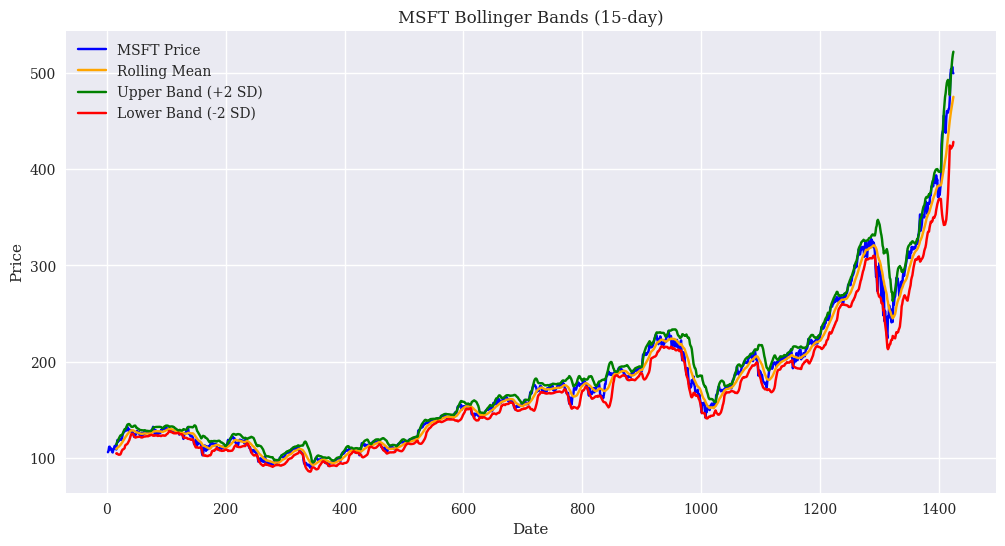

In [48]:
# plot
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.plot(msft_bollinger['prc'], label='MSFT Price', color='blue')
plt.plot(msft_bollinger['avg'], label='Rolling Mean', color='orange')
plt.plot(msft_bollinger['sd2up'], label='Upper Band (+2 SD)', color='green')
plt.plot(msft_bollinger['sd2down'], label='Lower Band (-2 SD)', color='red')
plt.title('MSFT Bollinger Bands (15-day)')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()
